In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from glob import glob

In [3]:
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import confusion_matrix

import cv2
import gc
import os

import tensorflow as tf
from tensorflow import keras
from keras import layers

import warnings
warnings.filterwarnings('ignore')



In [7]:
data_path = 'Downloads/New folder (19)/lung_colon_image_set'

path = 'Downloads/New folder (19)/lung_colon_image_set/lung_image_sets'
classes = os.listdir(path)
classes

path = 'Downloads/New folder (19)/lung_colon_image_set/lung_image_sets'
 


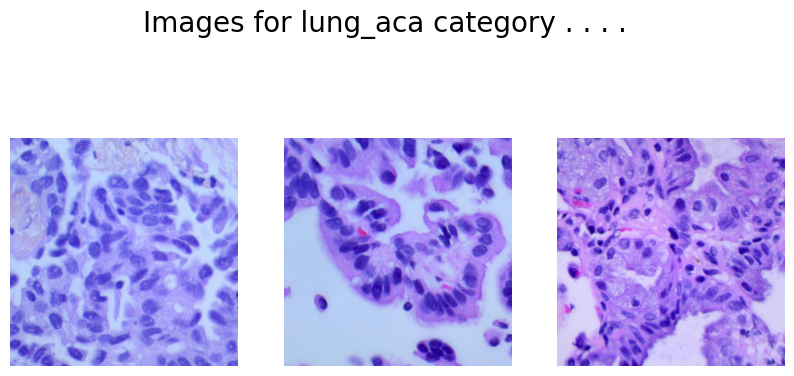

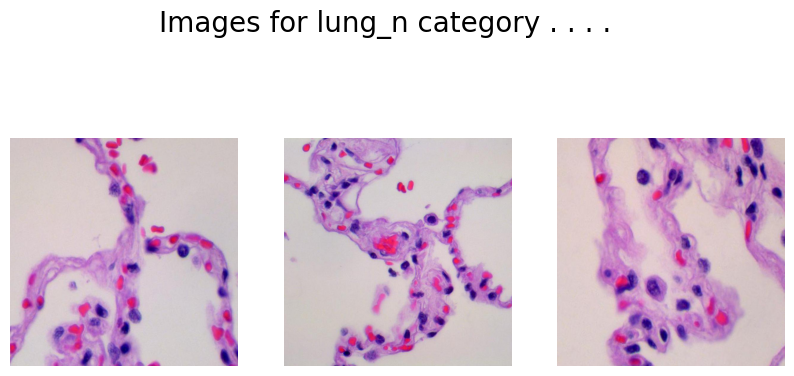

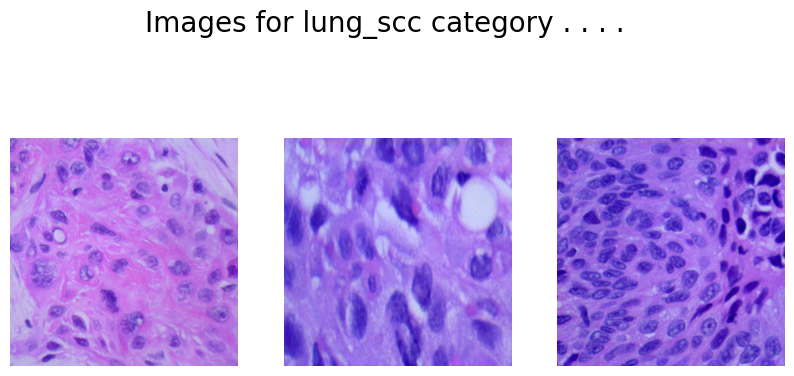

In [9]:
for cat in classes:
    image_dir = f'{path}/{cat}'
    images = os.listdir(image_dir)
 
    fig, ax = plt.subplots(1, 3, figsize=(10, 5))
    fig.suptitle(f'Images for {cat} category . . . .', fontsize=20)
 
    for i in range(3):
        k = np.random.randint(0, len(images))
        img = np.array(Image.open(f'{path}/{cat}/{images[k]}'))
        ax[i].imshow(img)
        ax[i].axis('off')
    plt.show()



In [11]:
img_size = 256
split = 0.2
epochs = 10
batch_size = 64

In [13]:
X = []
Y = []
 
for i, cat in enumerate(classes):
  images = glob(f'{path}/{cat}/*.jpeg')
 
  for image in images:
    img = cv2.imread(image)
     
    X.append(cv2.resize(img, (img_size,img_size)))
    Y.append(i)
 


In [14]:
X = np.asarray(X)
one_hot_encoded_Y = pd.get_dummies(Y).values

X_train, X_test, Y_train, Y_test = train_test_split(X, one_hot_encoded_Y,
                                                  test_size = split,
                                                  random_state = 2022)



In [61]:
X

array([[[[240, 195, 211],
         [241, 197, 210],
         [242, 198, 211],
         ...,
         [221,  85, 151],
         [223,  84, 151],
         [226,  87, 155]],

        [[241, 196, 212],
         [242, 198, 211],
         [243, 199, 212],
         ...,
         [218,  79, 147],
         [223,  83, 154],
         [225,  83, 154]],

        [[242, 197, 213],
         [243, 199, 212],
         [244, 200, 213],
         ...,
         [221,  84, 152],
         [219,  81, 152],
         [225,  85, 156]],

        ...,

        [[221, 113, 186],
         [218, 107, 187],
         [210,  99, 179],
         ...,
         [212, 118, 149],
         [221, 126, 160],
         [222, 128, 162]],

        [[218, 106, 178],
         [215, 101, 178],
         [206,  93, 173],
         ...,
         [221, 127, 158],
         [226, 132, 166],
         [234, 140, 174]],

        [[215, 100, 167],
         [212,  97, 170],
         [202,  91, 165],
         ...,
         [217, 127, 157],
        

In [63]:
one_hot_encoded_Y

array([[ True, False, False],
       [ True, False, False],
       [ True, False, False],
       ...,
       [False, False,  True],
       [False, False,  True],
       [False, False,  True]])

In [15]:
model = keras.models.Sequential([
	layers.Conv2D(filters=32,
				kernel_size=(5, 5),
				activation='relu',
				input_shape=(img_size,
							img_size,
							3),
				padding='same'),
	layers.MaxPooling2D(2, 2),

	layers.Conv2D(filters=64,
				kernel_size=(3, 3),
				activation='relu',
				padding='same'),
	layers.MaxPooling2D(2, 2),

	layers.Conv2D(filters=128,
				kernel_size=(3, 3),
				activation='relu',
				padding='same'),
	layers.MaxPooling2D(2, 2),

	layers.Flatten(),
	layers.Dense(256, activation='relu'),
	layers.BatchNormalization(),
	layers.Dense(128, activation='relu'),
	layers.Dropout(0.3),
	layers.BatchNormalization(),
	layers.Dense(3, activation='softmax')
])




In [59]:
model

<Sequential name=sequential, built=True>

In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 256, 256, 32)        │           2,432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 128, 128, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 128, 128, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 64, 64, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 64, 64, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 32, 32, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 131072)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │      33,554,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 33,684,291 (128.50 MB)

 Trainable params: 33,683,523 (128.49 MB)

 Non-trainable params: 768 (3.00 KB)

In [34]:
model.compile(
    optimizer = 'adam',
    loss = 'categorical_crossentropy',
    metrics = ['accuracy']
)



In [36]:
history = model.fit(X_train, Y_train,
                    validation_data = (X_test,Y_test),
                    batch_size = batch_size,
                    epochs = epochs,
                    verbose = 1)

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 392s 2s/step - accuracy: 0.8083 - loss: 0.4647 - val_accuracy: 0.3453 - val_loss: 8.4419
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 364s 2s/step - accuracy: 0.9130 - loss: 0.2180 - val_accuracy: 0.7980 - val_loss: 0.5616
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 376s 2s/step - accuracy: 0.9230 - loss: 0.1896 - val_accuracy: 0.3453 - val_loss: 12.7612
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 359s 2s/step - accuracy: 0.9452 - loss: 0.1438 - val_accuracy: 0.6240 - val_loss: 17.6755
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 351s 2s/step - accuracy: 0.9534 - loss: 0.1222 - val_accuracy: 0.6660 - val_loss: 7.3659
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 348s 2s/step - accuracy: 0.9602 - loss: 0.1114 - val_accuracy: 0.6670 - val_loss: 23.5480
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 348s 2s/step - accuracy: 0.9689 - loss: 0.0818 - val_accuracy: 0.5127 - val_loss: 3.7143
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 348s 2s/step - accuracy: 0.9790 - loss: 0.0580 - val_a

In [57]:
history

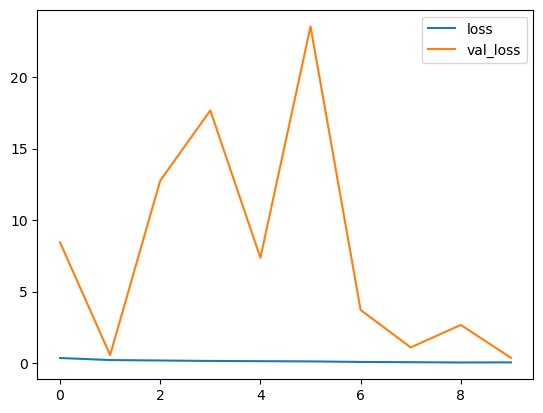

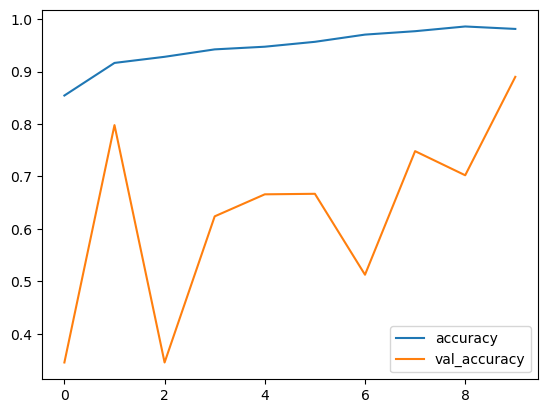

In [38]:
history_df = pd.DataFrame(history.history)
history_df.loc[:,['loss','val_loss']].plot()
history_df.loc[:,['accuracy','val_accuracy']].plot()
plt.show()

In [55]:
history_df

,accuracy,loss,val_accuracy,val_loss
0,0.854417,0.355906,0.345333,8.441885
1,0.916583,0.211584,0.798000,0.561639
2,0.928250,0.180487,0.345333,12.761178
3,0.942417,0.149918,0.624000,17.675533
4,0.947500,0.132908,0.666000,7.365892
5,0.956833,0.117429,0.667000,23.547995
6,0.970583,0.078996,0.512667,3.714315
7,0.977083,0.061304,0.748333,1.096208
8,0.986083,0.042179,0.702333,2.667271
9,0.981417,0.049653,0.890000,0.370928


In [40]:
Y_pred = model.predict(X_test)
Y_test = np.argmax(Y_test, axis=1)
Y_pred = np.argmax(Y_pred, axis=1)

94/94 ━━━━━━━━━━━━━━━━━━━━ 18s 187ms/step


In [51]:
Y_pred

array([0, 0, 2, ..., 1, 1, 1], dtype=int64)

In [53]:
Y_test

array([0, 2, 2, ..., 1, 1, 1], dtype=int64)

In [43]:

metrics.confusion_matrix(Y_test, Y_pred)



array([[833,  10, 144],
       [ 56, 921,   0],
       [118,   2, 916]], dtype=int64)

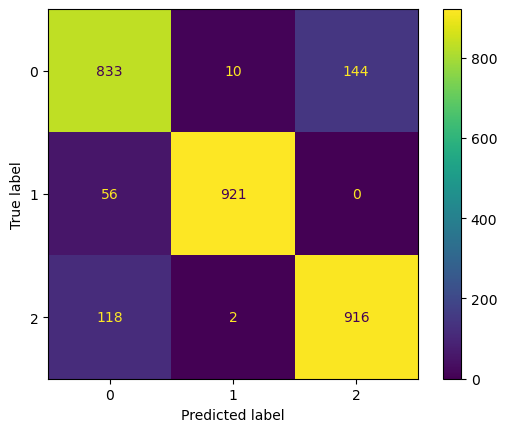

In [47]:
from sklearn.metrics import ConfusionMatrixDisplay

# Generate the confusaion matrix plot
ConfusionMatrixDisplay.from_predictions(Y_test, Y_pred, cmap='viridis')
plt.show()


In [49]:

print(metrics.classification_report(Y_test, Y_pred,
                                    target_names=classes))

              precision    recall  f1-score   support

    lung_aca       0.83      0.84      0.84       987
      lung_n       0.99      0.94      0.96       977
    lung_scc       0.86      0.88      0.87      1036

    accuracy                           0.89      3000
   macro avg       0.89      0.89      0.89      3000
weighted avg       0.89      0.89      0.89      3000

